# 02 — Baseline: SEIRD con β costante

Obiettivo: stimare i parametri del SEIRD con **β costante** in ogni finestra temporale. È il termine di confronto per il GP: β(t) dipendente dalla mobilità deve fare meglio di così.

Impostazione, come in Pianesi e Pojer:
- parametri stimati: β, σ, γ, μ e gli esposti iniziali E₀ (non osservati);
- condizioni iniziali di I, R, D prese dai dati del primo giorno della finestra;
- fitness = 0.9 · RMSD(decessi) + 0.1 · RMSD(positivi attuali);
- ottimizzatore: differential evolution (algoritmo evolutivo di scipy).

Sezioni:
1. Replica del primo esperimento del paper (dati `raw`, 1/3–1/4/2020)
2. Baseline con divisione train/test su tutte le finestre, `raw` e `clean`
3. Diagnostica: identificabilità dei parametri
4. Conclusioni e decisioni aperte

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, RESULTS_DIR
from seird_gp.fitting import DEFAULT_BOUNDS, fit_baseline, relative_fitness

data = {name: pd.read_csv(PROCESSED_DIR / f"trento_{name}.csv", index_col=0, parse_dates=True)
        for name in ["raw", "clean"]}
WINDOWS = {"2020 (1/3–1/4)": ("2020-03-01", "2020-04-01"),
           "2021 (1/3–1/6)": ("2021-03-01", "2021-06-01"),
           "2022 (1/1–1/3)": ("2022-01-01", "2022-03-01")}
TRAIN_FRAC = 2 / 3
RESULTS_DIR.mkdir(exist_ok=True)
pd.DataFrame(DEFAULT_BOUNDS, index=["min", "max"])

,beta,sigma,gamma,mu
min,0.01,0.071429,0.016667,0.00
max,2.00,0.500000,0.333333,0.05


In [2]:
def plot_fit(res, obs, title, ax_pair):
    for ax, model, col, label in [(ax_pair[0], "D", "deceduti", "Decessi (cumulativi)"),
                                  (ax_pair[1], "I", "totale_positivi", "Positivi attuali")]:
        ax.plot(obs.index, obs[col], "o", ms=3, color="#999", label="dati")
        ax.plot(res.simulation.index, res.simulation[model], color="#1f4e79", label="modello")
        if res.train_end < obs.index[-1]:
            ax.axvspan(res.train_end, obs.index[-1], color="#f4e3c1", alpha=0.6, label="test")
        ax.set_title(f"{title} — {label}", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="x", labelrotation=30, labelsize=8)

## 1. Replica del paper

Primo esperimento di Pianesi e Pojer: dati originali, 1/3–1/4/2020, fit su tutta la finestra. La loro Tabella I usa una parametrizzazione diversa (t_inf, f); la convertiamo:
- t_inf = 1 / (γ + μ): giorni medi in I
- f = μ / (γ + μ): frazione di chi esce da I che muore
- R0 = β / (γ + μ)

In [3]:
a, b = WINDOWS["2020 (1/3–1/4)"]
paper = fit_baseline(data["raw"], a, b, train_frac=1.0)
cmp = pd.DataFrame({
    "Pianesi e Pojer": {"beta": 0.47, "sigma": 1.52, "t_inf": 5.1, "f": 0.37, "fitness": 12.50},
    "nostro": {"beta": paper.params["beta"], "sigma": paper.params["sigma"],
               "t_inf": paper.derived()["t_inf"], "f": paper.derived()["f"],
               "fitness": paper.fitness_train},
}).round(3)
print("Parametri sul bordo dell'intervallo:", paper.extra["at_bound"])
cmp

Parametri sul bordo dell'intervallo: ['sigma', 'gamma']


,Pianesi e Pojer,nostro
beta,0.47,0.324
sigma,1.52,0.071
t_inf,5.10,36.906
f,0.37,0.385
fitness,12.50,24.179


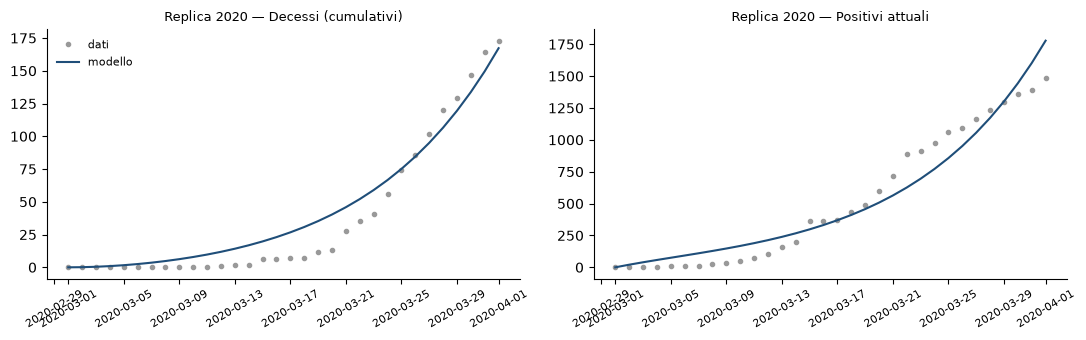

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
plot_fit(paper, data["raw"].loc[a:b], "Replica 2020", ax)
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "02_replica_paper.png", dpi=150)

**Lettura.**
- La frazione di decessi f è vicina a quella del paper (~0.38 contro 0.37).
- σ e t_inf sono molto diversi. Il paper ha σ = 1.52, cioè un'incubazione di meno di un giorno: biologicamente implausibile, possibile solo perché il loro intervallo per σ era più largo. Noi limitiamo l'incubazione a 2–14 giorni, e σ finisce sul bordo inferiore.
- La fitness è dello stesso ordine (circa 24 contro 12.5). Il confronto non è esatto perché nel paper t_inf era probabilmente fissato e gli intervalli dei parametri non sono riportati.

Conclusione: l'implementazione si comporta in modo coerente col paper, ma i parametri dipendono molto dagli intervalli, come scrivono anche gli autori.

## 2. Baseline train/test

In ogni finestra: fit sui primi 2/3 dei giorni, test sull'ultimo terzo. È la stessa divisione che useremo per il GP.

In [5]:
rows, fits = [], {}
t0 = time.time()
for ds in ["raw", "clean"]:
    for name, (a, b) in WINDOWS.items():
        res = fit_baseline(data[ds], a, b, train_frac=TRAIN_FRAC)
        fits[(ds, name)] = res
        rows.append({"dataset": ds, "finestra": name, **res.params, **res.derived(),
                     "RMSD D train": res.rmsd.loc["train", "D"], "RMSD D test": res.rmsd.loc["test", "D"],
                     "RMSD I train": res.rmsd.loc["train", "I"], "RMSD I test": res.rmsd.loc["test", "I"],
                     "fitness test": res.rmsd.loc["test", "fitness"],
                     "al bordo": ", ".join(res.extra["at_bound"])})
print(f"{len(rows)} fit in {time.time() - t0:.0f} s")
baseline = pd.DataFrame(rows).set_index(["dataset", "finestra"])
baseline.round(3)

6 fit in 86 s


beta  sigma  gamma     mu         E0      R0   t_inf  \
dataset finestra                                                                
raw     2020 (1/3–1/4)  0.789  0.071  0.017  0.005    108.053  36.044  45.694   
        2021 (1/3–1/6)  0.010  0.071  0.056  0.001   5369.442   0.177  17.729   
        2022 (1/1–1/3)  0.567  0.500  0.333  0.000  12451.128   1.702   2.999   
clean   2020 (1/3–1/4)  0.782  0.071  0.017  0.004    119.050  37.594  48.096   
        2021 (1/3–1/6)  0.010  0.071  0.056  0.001   5369.442   0.177  17.729   
        2022 (1/1–1/3)  0.567  0.500  0.333  0.000  12451.128   1.702   2.999   

                            f  RMSD D train  RMSD D test  RMSD I train  \
dataset finestra                                                         
raw     2020 (1/3–1/4)  0.238         2.428       28.822        40.935   
        2021 (1/3–1/6)  0.013         7.360       10.706       169.601   
        2022 (1/1–1/3)  0.000         2.272       16.164      1186.599   
clean   2020 (1/3–1/4)  0.198         2.114       25.324        44.334   
        2021 (1/3–1/6)  0.013         7.360       10.706       169.601   
        2022 (1/1–1/3)  0.000         2.272       16.164      1186.599   

                        RMSD I test  fitness test          al bordo  
dataset finestra                                                     
raw     2020 (1/3–1/4)     2185.583       244.498      sigma, gamma  
        2021 (1/3–1/6)      169.680        26.603       beta, sigma  
        2022 (1/1–1/3)     1083.191       122.867  sigma, gamma, mu  
clean   2020 (1/3–1/4)     2345.604       257.352      sigma, gamma  
        2021 (1/3–1/6)      169.680        26.603       beta, sigma  
        2022 (1/1–1/3)     1083.191       122.867  sigma, gamma, mu

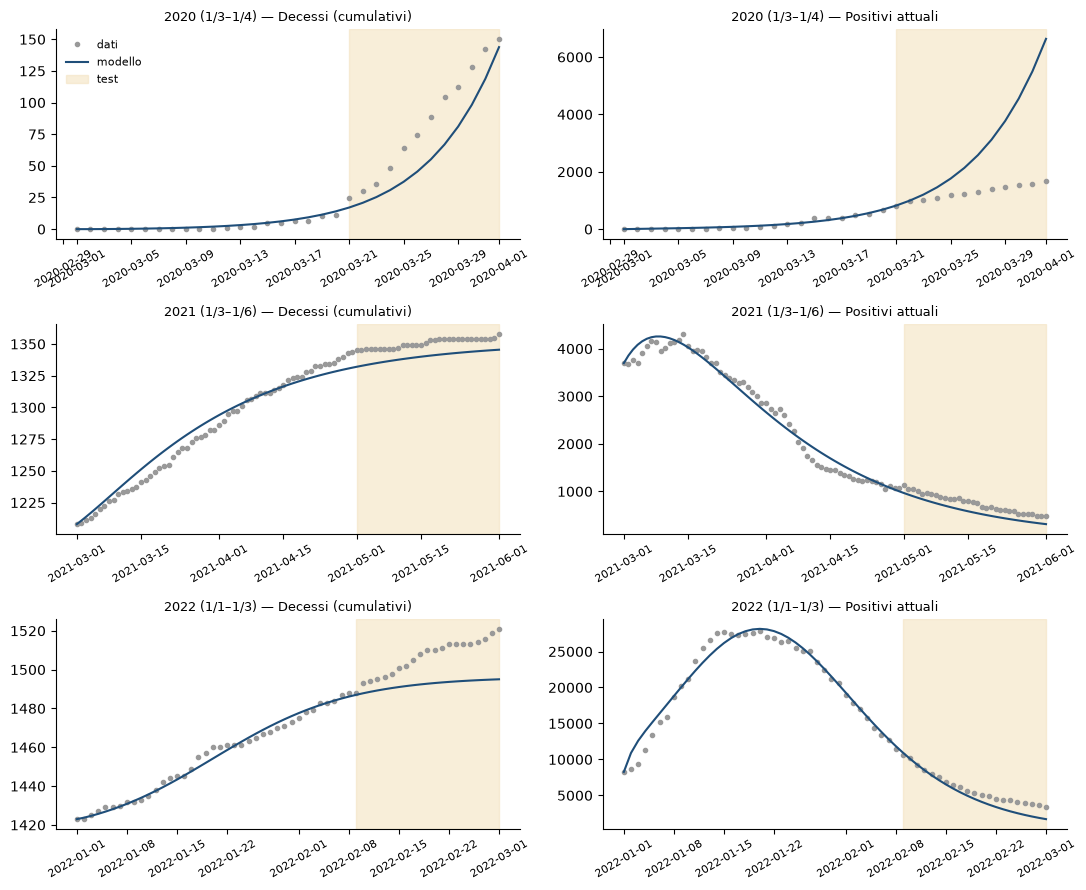

In [6]:
fig, ax = plt.subplots(3, 2, figsize=(11, 9))
for i, name in enumerate(WINDOWS):
    a, b = WINDOWS[name]
    plot_fit(fits[("clean", name)], data["clean"].loc[a:b], name, ax[i])
ax[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "02_baseline_clean.png", dpi=150)

In [7]:
baseline.to_csv(RESULTS_DIR / "02_baseline.csv")

## 3. Diagnostica: identificabilità

Molti parametri finiscono sul bordo dell'intervallo. Significa che l'ottimizzatore vorrebbe andare oltre, oppure che il valore non conta perché combinazioni diverse danno curve quasi uguali. In entrambi i casi i parametri non sono **identificabili** dai soli dati di D e I.

Tre controlli sui dati `clean`:
- **(a) seed diversi**: se i parametri cambiano molto da un seed all'altro, non sono determinati dai dati;
- **(b) σ fissato** a 1/5.2 (incubazione media di letteratura): toglie un grado di libertà;
- **(c) fitness relativa con i guariti**: errori normalizzati e R confrontato con `dimessi_guariti`, per vincolare γ.

In [8]:
rows = []
for name, (a, b) in WINDOWS.items():
    for seed in [1, 2]:
        r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, seed=seed)
        rows.append({"finestra": name, "variante": f"(a) seed {seed}", **r.params, **r.derived(),
                     "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                     "al bordo": ", ".join(r.extra["at_bound"])})
    r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, fixed={"sigma": 1 / 5.2})
    rows.append({"finestra": name, "variante": "(b) σ = 1/5.2", **r.params, **r.derived(),
                 "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                 "al bordo": ", ".join(r.extra["at_bound"])})
    r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, fixed={"sigma": 1 / 5.2},
                     fitness_fn=relative_fitness)
    rows.append({"finestra": name, "variante": "(c) σ fisso + fitness relativa", **r.params, **r.derived(),
                 "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                 "al bordo": ", ".join(r.extra["at_bound"])})
base_rows = baseline.loc["clean"].reset_index().assign(variante="seed 0 (sezione 2)")
diag = pd.concat([base_rows, pd.DataFrame(rows)])
cols = ["finestra", "variante", "beta", "sigma", "gamma", "mu", "E0", "R0", "RMSD D test", "RMSD I test", "al bordo"]
diag = diag[cols].sort_values(["finestra", "variante"]).set_index(["finestra", "variante"])
diag.to_csv(RESULTS_DIR / "02_diagnostica.csv")
diag.round(3)

beta  sigma  gamma     mu  \
finestra       variante                                                     
2020 (1/3–1/4) (a) seed 1                      0.782  0.071  0.017  0.004   
               (a) seed 2                      0.782  0.071  0.017  0.004   
               (b) σ = 1/5.2                   0.428  0.192  0.017  0.004   
               (c) σ fisso + fitness relativa  1.046  0.192  0.017  0.010   
               seed 0 (sezione 2)              0.782  0.071  0.017  0.004   
2021 (1/3–1/6) (a) seed 1                      0.338  0.500  0.333  0.001   
               (a) seed 2                      0.010  0.071  0.056  0.001   
               (b) σ = 1/5.2                   0.010  0.192  0.037  0.001   
               (c) σ fisso + fitness relativa  0.053  0.192  0.073  0.001   
               seed 0 (sezione 2)              0.010  0.071  0.056  0.001   
2022 (1/1–1/3) (a) seed 1                      0.567  0.500  0.333  0.000   
               (a) seed 2                      0.567  0.500  0.333  0.000   
               (b) σ = 1/5.2                   0.607  0.192  0.333  0.000   
               (c) σ fisso + fitness relativa  0.069  0.192  0.068  0.000   
               seed 0 (sezione 2)              0.567  0.500  0.333  0.000   

                                                      E0      R0  RMSD D test  \
finestra       variante                                                         
2020 (1/3–1/4) (a) seed 1                        119.055  37.593       25.324   
               (a) seed 2                        119.041  37.596       25.321   
               (b) σ = 1/5.2                      54.190  20.607       24.834   
               (c) σ fisso + fitness relativa      3.590  39.759      317.273   
               seed 0 (sezione 2)                119.050  37.594       25.324   
2021 (1/3–1/6) (a) seed 1                       3912.311   1.013        7.197   
               (a) seed 2                       5369.459   0.177       10.706   
               (b) σ = 1/5.2                    2300.941   0.262        7.656   
               (c) σ fisso + fitness relativa   2502.658   0.718        4.852   
               seed 0 (sezione 2)               5369.442   0.177       10.706   
2022 (1/1–1/3) (a) seed 1                      12451.175   1.702       16.165   
               (a) seed 2                      12450.980   1.702       16.168   
               (b) σ = 1/5.2                   38304.891   1.821       12.495   
               (c) σ fisso + fitness relativa  26923.228   1.011        4.832   
               seed 0 (sezione 2)              12451.128   1.702       16.164   

                                               RMSD I test          al bordo  
finestra       variante                                                       
2020 (1/3–1/4) (a) seed 1                         2345.579      sigma, gamma  
               (a) seed 2                         2345.917      sigma, gamma  
               (b) σ = 1/5.2                      2419.920             gamma  
               (c) σ fisso + fitness relativa    13009.152         gamma, E0  
               seed 0 (sezione 2)                 2345.604      sigma, gamma  
2021 (1/3–1/6) (a) seed 1                           46.243      sigma, gamma  
               (a) seed 2                          169.686       beta, sigma  
               (b) σ = 1/5.2                        32.281              beta  
               (c) σ fisso + fitness relativa      401.052                    
               seed 0 (sezione 2)                  169.680       beta, sigma  
2022 (1/1–1/3) (a) seed 1                         1083.206  sigma, gamma, mu  
               (a) seed 2                         1083.187  sigma, gamma, mu  
               (b) σ = 1/5.2                      2405.812         gamma, mu  
               (c) σ fisso + fitness relativa    10554.214                mu  
               seed 0 (sezione 2)                 1083.191  sigma, gamma, mu

## 4. Conclusioni

- **Il codice funziona**: sui dati sintetici (test in `tests/test_fitting.py`) il fit ritrova i parametri veri, e sul 2020 il risultato è coerente con il paper.
- **I parametri del SEIRD a β costante non sono identificabili** dai soli decessi e positivi: finiscono sui bordi e cambiano con le scelte di modellazione (σ fisso, fitness). Le curve fittate però sono simili. Va tenuto presente quando si interpretano i valori numerici: conta l'errore, non i singoli parametri.
- **β costante non può seguire i cambi di fase.** Nella finestra 2020 c'è il lockdown (9/3/2020), nella 2021 l'epidemia è in calo. Il modello compensa con valori estremi (R0 ≈ 37 nel 2020, β al minimo nel 2021) e sbaglia nel periodo di test: nel 2020 prevede una crescita esponenziale che il lockdown ha fermato (RMSD sui positivi in test > 2000). È proprio la limitazione che il GP con β(t) deve superare.
- `raw` e `clean` differiscono solo nel 2020, e di poco.

Il numero da battere per il GP è la colonna **fitness test** della tabella in sezione 2 (salvata in `results/02_baseline.csv`).

## Decisioni aperte

1. **Quale fitness usare d'ora in poi.** Quella del paper (0.9/0.1 su RMSD assolute) fa pesare molto gli infetti, perché sono migliaia mentre i decessi sono decine. La versione relativa (c) bilancia i termini e usa anche i guariti. Proposta: tenere quella del paper per confrontarsi con loro, e decidere quale usare per il GP.
2. **Fissare σ dalla letteratura?** Riduce un grado di libertà senza costi evidenti. Con β(t) il problema di identificabilità aumenta, perché i gradi di libertà sono di più, quindi fissare ciò che si può fissare aiuta.
3. **Le finestre.** Quelle del paper sono brevi (1–3 mesi). Per il GP potrebbero servire finestre più lunghe con variazioni di mobilità, per esempio da settembre 2020 a febbraio 2021 per la seconda ondata.